In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

df = pd.read_excel("../data/processed/cleaned_cars.xlsx")

print(df.shape)

df.head()
drop_columns = [

    "title",
    "url",
    "ad_ref",
    "last_updated",
    "auction_grade",
    "import_date",
    "chassis_no",
    "features"

]

df = df.drop(columns=drop_columns)

print(df.shape)

print(df.isnull().sum()[df.isnull().sum() > 0])
df["body_type"] = df["body_type"].fillna("Unknown")

df["variant"] = df["variant"].fillna("Unknown")
df = df.dropna(subset=["price_pkr"])
df.isnull().sum().sum()
X = df.drop(columns=["price_pkr"])

y = df["price_pkr"]

print(X.shape)

print(y.shape)
categorical_columns = X.select_dtypes(include="object").columns.tolist()

numerical_columns = X.select_dtypes(exclude="object").columns.tolist()

print("Categorical Columns")

print(categorical_columns)

print()

print("Numerical Columns")

print(numerical_columns)


(7835, 53)
(7835, 45)
price_pkr     57
body_type    284
variant      260
dtype: int64
(7778, 44)
(7778,)
Categorical Columns
['registered_city', 'color', 'assembly', 'body_type', 'brand', 'model', 'variant']

Numerical Columns
['engine_cc', 'year', '360_camera', 'abs', 'air_bags', 'air_conditioning', 'alloy_wheels', 'android_auto', 'apple_carplay', 'climate_control', 'cruise_control', 'drls', 'front_camera', 'front_fog_lights', 'front_speakers', 'head_up_display_(hud)', 'heated_seats', 'immobilizer_key', 'infotainment_system', 'keyless_entry', 'led_headlights', 'paddle_shifters', 'panoramic_sunroof', 'parking_sensors', 'power_locks', 'power_mirrors', 'power_seats', 'power_steering', 'push_start', 'rear_ac_vents', 'rear_camera', 'rear_speakers', 'steering_switches', 'sun_roof', 'traction_control', 'tyre_pressure_monitoring_system_(tpms)', 'ventilated_seats']


In [3]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[

        (
            "num",
            numeric_transformer,
            numerical_columns
        ),

        (
            "cat",
            categorical_transformer,
            categorical_columns
        )
    ]
)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42
)
print(X_train.shape)

print(X_test.shape)

(6222, 44)
(1556, 44)


In [5]:
from sklearn.linear_model import LinearRegression

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [6]:
predictions = model.predict(X_test)

predictions[:10]

array([1026808.05018556, 1871651.77306736, 6867441.56362796,
       5703839.47227591, 1163815.84392172, 5326937.62561601,
       2734739.37969488, 2655015.00899589, 1353963.01234525,
       1159649.03474265])

In [7]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

r2 = r2_score(
    y_test,
    predictions
)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 319790.37453256117
RMSE: 597197.1681237343
R²  : 0.9575424517070261


In [8]:
from sklearn.tree import DecisionTreeRegressor

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                random_state=42,
                max_depth=20,
                min_samples_leaf=2
            )
        )
    ]
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

In [9]:
tree_mae = mean_absolute_error(
    y_test,
    tree_predictions
)

tree_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tree_predictions
    )
)

tree_r2 = r2_score(
    y_test,
    tree_predictions
)

print("Decision Tree")
print("--------------------")
print("MAE :", tree_mae)
print("RMSE:", tree_rmse)
print("R²  :", tree_r2)

Decision Tree
--------------------
MAE : 308374.2472004511
RMSE: 642765.1047938726
R²  : 0.950815980794343


In [10]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=25,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [11]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest")
print("--------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest
--------------------
MAE : 270161.9621442434
RMSE: 581782.9365474179
R²  : 0.9597059063206218


In [12]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=5,
                min_samples_leaf=3,
                random_state=42
            )
        )
    ]
)

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)

In [13]:
gb_mae = mean_absolute_error(
    y_test,
    gb_predictions
)

gb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        gb_predictions
    )
)

gb_r2 = r2_score(
    y_test,
    gb_predictions
)

print("Gradient Boosting")
print("--------------------")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R²  :", gb_r2)

Gradient Boosting
--------------------
MAE : 280332.94372070197
RMSE: 579548.1638019822
R²  : 0.9600148710154303


In [14]:
%pip install xgboost


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [15]:
from xgboost import XGBRegressor

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBRegressor(
                n_estimators=500,
                learning_rate=0.05,
                max_depth=6,
                min_child_weight=2,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

In [16]:
xgb_mae = mean_absolute_error(
    y_test,
    xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_predictions
    )
)

xgb_r2 = r2_score(
    y_test,
    xgb_predictions
)

print("XGBoost")
print("--------------------")
print("MAE :", xgb_mae)
print("RMSE:", xgb_rmse)
print("R²  :", xgb_r2)

XGBoost
--------------------
MAE : 257690.77695212082
RMSE: 513366.67029775085
R²  : 0.9686256475211227


In [17]:
# Check exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Check duplicate car combinations
duplicate_groups = df.groupby(
    ["brand", "model", "year", "variant"]
).size().sort_values(ascending=False)

print(duplicate_groups.head(20))

Exact duplicate rows: 191
brand   model    year  variant        
Suzuki  Cultus   2007  VXR                180
                 2006  VXR                153
                 2008  VXRi               146
                 2005  VXR                120
                 2014  EURO II            110
                 2016  Limited Edition     99
                 2021  VXL                 91
                 2018  VXR                 90
                 2015  EURO II             84
                 2019  VXL                 83
                 2013  EURO II             80
        Alto     2022  VXR                 68
        Cultus   2018  VXL                 66
                 2021  VXR                 66
                 2011  VXRi                65
Toyota  Corolla  2024  Cross 1.8 HEV X     62
Suzuki  Cultus   2004  VXR                 62
                 2010  VXRi                62
                 2021  Auto Gear Shift     58
                 2012  EURO II             57
dtype: int64


In [18]:
print(
    df[
        ["brand", "model", "year", "variant", "price_pkr"]
    ].head(20)
)

     brand model  year           variant  price_pkr
1   Suzuki  Alto  2022                VX  2600000.0
2   Suzuki  Alto  2023          Hybrid S  3850000.0
3   Suzuki  Alto  2019           VXL AGS  2630000.0
4   Suzuki  Alto  2023           VXL AGS  3095000.0
5   Suzuki  Alto  2025           VXL AGS  3095000.0
6   Suzuki  Alto  2012               VXR  1300000.0
7   Suzuki  Alto  2022               VXR  2650000.0
8   Suzuki  Alto  2012               VXR  1100000.0
9   Suzuki  Alto  2011             ECO-S  2375000.0
10  Suzuki  Alto  2026  VXL AGS Upgraded  3485000.0
11  Suzuki  Alto  2021          TURBO RS  3975000.0
12  Suzuki  Alto  2007               VXR   875000.0
13  Suzuki  Alto  2025               VXR  2815000.0
14  Suzuki  Alto  2014             ECO-L  2250000.0
15  Suzuki  Alto  2020               VXR  2440000.0
16  Suzuki  Alto  2024               VXR  2890000.0
17  Suzuki  Alto  2022               VXR  2585000.0
18  Suzuki  Alto  2021           VXL AGS  2700000.0
19  Suzuki  

In [19]:
df = df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 7587


In [20]:
from sklearn.model_selection import GroupShuffleSplit

groups = (
    df["brand"].astype(str)
    + "_"
    + df["model"].astype(str)
    + "_"
    + df["year"].astype(str)
    + "_"
    + df["variant"].astype(str)
)

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(df, groups=groups)
)

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

print("Train:", train_df.shape)
print("Test :", test_df.shape)

Train: (5970, 45)
Test : (1617, 45)


In [21]:
X_train = train_df.drop(columns=["price_pkr"])
y_train = train_df["price_pkr"]

X_test = test_df.drop(columns=["price_pkr"])
y_test = test_df["price_pkr"]

In [23]:
xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

In [24]:
xgb_mae = mean_absolute_error(
    y_test,
    xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_predictions
    )
)

xgb_r2 = r2_score(
    y_test,
    xgb_predictions
)

print("XGBoost - Group Validation")
print("----------------------------")
print("MAE :", xgb_mae)
print("RMSE:", xgb_rmse)
print("R²  :", xgb_r2)

XGBoost - Group Validation
----------------------------
MAE : 266178.150085034
RMSE: 640130.8258347355
R²  : 0.956127392120313


In [25]:
xgb_baseline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            XGBRegressor(
                n_estimators=500,
                learning_rate=0.05,
                max_depth=6,
                min_child_weight=2,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)
xgb_baseline.fit(
    X_train,
    y_train
)
baseline_predictions = (
    xgb_baseline.predict(X_test)
)
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print("Final XGBoost Baseline")
print("----------------------------")
print("MAE :", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²  :", baseline_r2)

Final XGBoost Baseline
----------------------------
MAE : 266178.150085034
RMSE: 640130.8258347355
R²  : 0.956127392120313


In [26]:
from sklearn.model_selection import RandomizedSearchCV
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBRegressor(
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)
param_grid = {
    "model__n_estimators": [
        300,
        500,
        700,
        900
    ],

    "model__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.08,
        0.1
    ],

    "model__max_depth": [
        3,
        4,
        5,
        6,
        8
    ],

    "model__min_child_weight": [
        1,
        2,
        3,
        5
    ],

    "model__subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__colsample_bytree": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__gamma": [
        0,
        0.1,
        0.2,
        0.5
    ]
}

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(
    X_train,
    y_train
)

print("Best Parameters:")
print(random_search.best_params_)

print(
    "Best CV MAE:",
    -random_search.best_score_
)

tuned_predictions = (
    random_search.best_estimator_.predict(
        X_test
    )
)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_predictions
    )
)

tuned_r2 = r2_score(
    y_test,
    tuned_predictions
)

print("Tuned XGBoost")
print("----------------------------")
print("MAE :", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²  :", tuned_r2)

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 700, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__gamma': 0.5, 'model__colsample_bytree': 0.7}
Best CV MAE: 585011.6362829773
Tuned XGBoost
----------------------------
MAE : 258496.13439239332
RMSE: 604387.107178246
R²  : 0.9608901319669418


In [27]:
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
group_cv = GroupKFold(n_splits=3)

group_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=group_cv,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

group_search.fit(
    X_train,
    y_train,
    groups=groups.iloc[train_idx]
)

print("Best Group Parameters:")
print(group_search.best_params_)

print(
    "Best Group CV MAE:",
    -group_search.best_score_
)

group_tuned_predictions = (
    group_search.best_estimator_.predict(X_test)
)

group_tuned_mae = mean_absolute_error(
    y_test,
    group_tuned_predictions
)

group_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        group_tuned_predictions
    )
)

group_tuned_r2 = r2_score(
    y_test,
    group_tuned_predictions
)

print("Group-Tuned XGBoost")
print("----------------------------")
print("MAE :", group_tuned_mae)
print("RMSE:", group_tuned_rmse)
print("R²  :", group_tuned_r2)

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best Group Parameters:
{'model__subsample': 0.7, 'model__n_estimators': 900, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__gamma': 0.5, 'model__colsample_bytree': 0.8}
Best Group CV MAE: 314144.01412662264
Group-Tuned XGBoost
----------------------------
MAE : 271167.1471378324
RMSE: 620403.7248254261
R²  : 0.9587897963225799


In [28]:
best_model = group_search.best_estimator_

xgb_estimator = best_model.named_steps["model"]

preprocessor_fitted = best_model.named_steps["preprocessor"]

feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

importances = xgb_estimator.feature_importances_

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

feature_importance = (
    feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
)

feature_importance.head(20)

plt.figure(figsize=(10, 8))

top_features = feature_importance.head(15)

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Affecting Car Price")

plt.show()
feature_importance.head(20)

NameError: name 'plt' is not defined

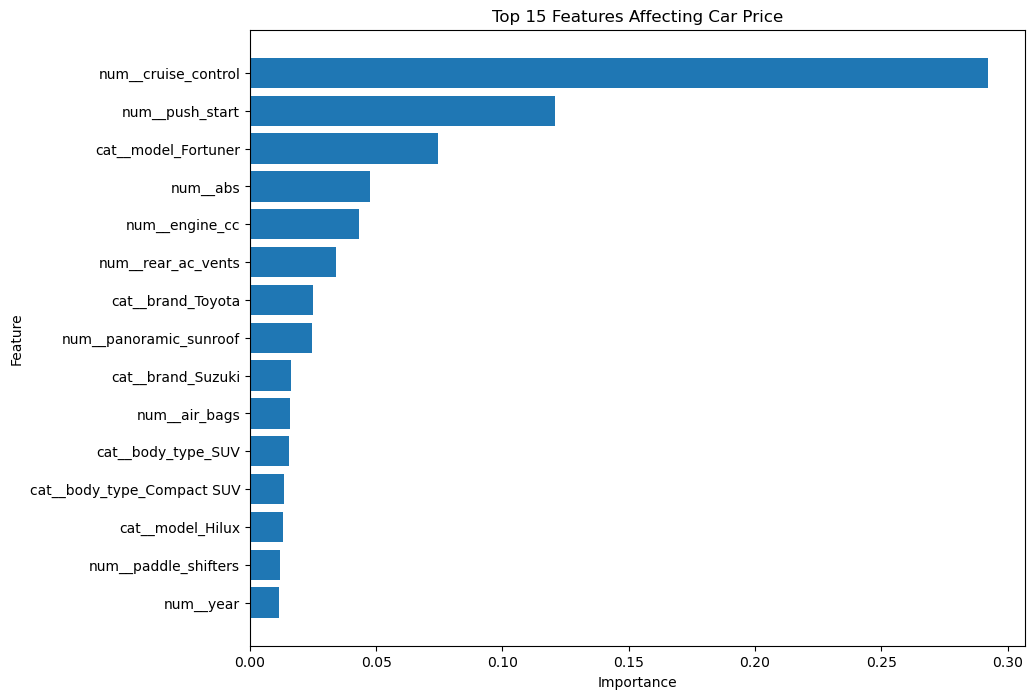

                   feature  importance
       num__cruise_control    0.292248
           num__push_start    0.120756
       cat__model_Fortuner    0.074613
                  num__abs    0.047510
            num__engine_cc    0.043234
        num__rear_ac_vents    0.033980
         cat__brand_Toyota    0.025165
    num__panoramic_sunroof    0.024475
         cat__brand_Suzuki    0.016361
             num__air_bags    0.015900
        cat__body_type_SUV    0.015673
cat__body_type_Compact SUV    0.013344
          cat__model_Hilux    0.013233
      num__paddle_shifters    0.011794
                 num__year    0.011402
        num__rear_speakers    0.011261
           num__360_camera    0.008956
             cat__brand_MG    0.008400
    cat__body_type_Pick Up    0.008223
num__head_up_display_(hud)    0.007941


In [29]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))

top_features = feature_importance.head(15)

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Affecting Car Price")

plt.show()
print(feature_importance.head(20).to_string(index=False))

In [30]:
print(feature_importance.head(30).to_string(index=False))

                           feature  importance
               num__cruise_control    0.292248
                   num__push_start    0.120756
               cat__model_Fortuner    0.074613
                          num__abs    0.047510
                    num__engine_cc    0.043234
                num__rear_ac_vents    0.033980
                 cat__brand_Toyota    0.025165
            num__panoramic_sunroof    0.024475
                 cat__brand_Suzuki    0.016361
                     num__air_bags    0.015900
                cat__body_type_SUV    0.015673
        cat__body_type_Compact SUV    0.013344
                  cat__model_Hilux    0.013233
              num__paddle_shifters    0.011794
                         num__year    0.011402
                num__rear_speakers    0.011261
                   num__360_camera    0.008956
                     cat__brand_MG    0.008400
            cat__body_type_Pick Up    0.008223
        num__head_up_display_(hud)    0.007941
       cat__b

In [31]:
import os

os.makedirs("../models", exist_ok=True)

import joblib

joblib.dump(
    group_search.best_estimator_,
    "../models/pak_car_price_xgboost.pkl"
)

print("Model saved successfully!")

feature_importance.to_csv(
    "../models/feature_importance.csv",
    index=False
)

print("Feature importance saved!")

Model saved successfully!
Feature importance saved!
